# This calibration is being done after moving Daedalus to it's new home near the shielded dil fridge

In [319]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hvplot.xarray
from analysis import *
from scipy.optimize import root

# First center calibrate after shimming

### Shimmed Fine raster sweep

In [2]:
phi0 = pd.read_csv('./2019-11-22/shim_coarse_0_fieldRaster_2019-11-22_1.csv',comment='#')
phi90 = pd.read_csv('./2019-11-22/shim_coarse_90_fieldRaster_2019-11-22_1.csv',comment='#')

In [3]:
lox = 11
hix = 14.5
stepx = 0.1
loy = 12
hiy = 15
stepy = 0.1
xpts = np.arange(lox, hix + stepx, stepx)
ypts = np.arange(loy, hiy + stepy, stepy)

In [18]:
phi0_dv = {}
phi90_dv = {}
for c in phi0.columns:
    phi0_dv[c] = (["Yc", "Xc"], phi0[c].values.reshape(ypts.size, xpts.size))
    phi90_dv[c] = (["Yc", "Xc"], phi90[c].values.reshape(ypts.size, xpts.size))

In [19]:
coords = {'Xc': ('Xc', xpts), 'Yc': ('Yc', ypts)}

In [20]:
phi0_ds = xr.Dataset(phi0_dv, coords)
phi90_ds = xr.Dataset(phi90_dv, coords)

In [36]:
phi0_ds.Yfield_avg.hvplot()

:Image   [Yc,Xc]   (Yfield_avg)

In [37]:
Zfield_mod = (phi90_ds.Zfield_avg**2 + phi0_ds.Zfield_avg**2)
print(Zfield_mod.where(Zfield_mod == Zfield_mod.min(), drop=True))
Zfield_mod.hvplot(title = "Combined 0 and 90 Z field")

<xarray.DataArray 'Zfield_avg' (Yc: 1, Xc: 1)>
array([[9.47264958e-07]])
Coordinates:
  * Xc       (Xc) float64 12.1
  * Yc       (Yc) float64 14.3


:Image   [Yc,Xc]   (Zfield_avg)

In [38]:
Yfield_mod = (phi90_ds.Xfield_avg**2 + phi0_ds.Yfield_avg**2)
print(Yfield_mod.where(Yfield_mod == Yfield_mod.max(), drop=True))
Yfield_mod.hvplot(title="Combined 0 and 90 Y field")

<xarray.DataArray (Yc: 1, Xc: 1)>
array([[0.07382186]])
Coordinates:
  * Xc       (Xc) float64 12.1
  * Yc       (Yc) float64 14.3


:Image   [Yc,Xc]   (value)

## Fine shimmed calibration

In [39]:
phi0f = pd.read_csv('./2019-11-22/shim_fine_0_fieldRaster_2019-11-22_1.csv',comment='#')
phi90f = pd.read_csv('./2019-11-22/shim_fine_90_fieldRaster_2019-11-22_1.csv',comment='#')

In [42]:
loxf = 11.9
hixf = 12.3
stepxf = 0.02
loyf = 14.1
hiyf = 14.5
stepyf = 0.02
xptsf = np.arange(loxf, hixf + stepxf, stepxf)
yptsf = np.arange(loyf, hiyf + stepyf, stepyf)

In [43]:
phi0f_dv = {}
phi90f_dv = {}
for c in phi0f.columns:
    phi0f_dv[c] = (["Yc", "Xc"], phi0f[c].values.reshape(yptsf.size, xptsf.size))
    phi90f_dv[c] = (["Yc", "Xc"], phi90f[c].values.reshape(yptsf.size, xptsf.size))

In [44]:
coordsf = {'Xc': ('Xc', xptsf), 'Yc': ('Yc', yptsf)}

In [45]:
phi0f_ds = xr.Dataset(phi0f_dv, coordsf)
phi90f_ds = xr.Dataset(phi90f_dv, coordsf)

In [ ]:
phi90f_ds

In [59]:
phi90f_ds.Yfield_avg.hvplot()

:Image   [Yc,Xc]   (Yfield_avg)

In [67]:
Zfieldf_mod = (phi90f_ds.Zfield_avg**2 + phi0f_ds.Zfield_avg**2)
print(Zfieldf_mod.where(Zfieldf_mod == Zfieldf_mod.min(), drop=True))
((Zfieldf_mod-Zfieldf_mod.mean())/Zfieldf_mod.mean()).hvplot(title = "Combined 0 and 90 Z field")

<xarray.DataArray 'Zfield_avg' (Yc: 1, Xc: 1)>
array([[3.56718214e-09]])
Coordinates:
  * Xc       (Xc) float64 12.06
  * Yc       (Yc) float64 14.3


:Image   [Yc,Xc]   (Zfield_avg)

In [61]:
phi0f_ds.Zfield_avg.hvplot()

:Image   [Yc,Xc]   (Zfield_avg)

In [66]:
Yfieldf_mod = (phi90f_ds.Xfield_avg**2 + phi0f_ds.Yfield_avg**2)
print(Yfieldf_mod.where(Yfieldf_mod == Yfieldf_mod.max(), drop=True))
((Yfieldf_mod-Yfieldf_mod.mean())/Yfieldf_mod.mean()).hvplot(title="Combined 0 and 90 Y field")

<xarray.DataArray (Yc: 1, Xc: 1)>
array([[0.07376716]])
Coordinates:
  * Xc       (Xc) float64 12.12
  * Yc       (Yc) float64 14.36


:Image   [Yc,Xc]   (value)

Really doesn't look great... It may be that it's so flat here that it's kinda impossible to pick out the Yfield maximum. As plotted, we are looking at the deviations, which are tiny, at most 0.06%. In the Z field we have up to 2% deviation.

# Seems like for the shimmed system, (12.06, 14.30) is pretty good

# Voltage/Field Calibration at Center

In [72]:
VB_0 = pd.read_csv('./2019-11-22/shim_0_daedalus_voltCenter_calib_2019-11-22_1.csv',comment='#')
VB_0 = VB_0.assign(phi=lambda x: np.arctan2(x.Xfield, x.Yfield)*180/np.pi)
VB_45 = pd.read_csv('./2019-11-22/shim_45_daedalus_voltCenter_calib_2019-11-22_1.csv',comment='#')
VB_45 = VB_45.assign(phi=lambda x: np.arctan2(x.Xfield, x.Yfield)*180/np.pi)
VB_45 = VB_45.assign(IPfield = lambda x: np.sqrt(x.Xfield**2+x.Yfield**2))
VB_90 = pd.read_csv('./2019-11-22/shim_90_daedalus_voltCenter_calib_2019-11-22_1.csv',comment='#')
VB_90 = VB_90.assign(phi=lambda x: np.arctan2(x.Xfield, x.Yfield)*180/np.pi)

In [90]:
VB_0.phi%90

0      0.434922
1      0.422257
2      0.439710
3      0.431387
4      0.435270
         ...   
397    0.436966
398    0.428945
399    0.427283
400    0.443154
401    0.440902
Name: phi, Length: 402, dtype: float64

In [96]:
VB_0

,V,Xfield,Yfield,Zfield,elapsed_time,phi
0,-10.0,-0.002128,-0.280306,-0.003688,6.564376,-179.565078
1,-9.9,-0.002056,-0.278907,-0.003686,7.060404,-179.577743
2,-9.8,-0.002131,-0.277621,-0.003581,7.555432,-179.560290
3,-9.7,-0.002080,-0.276249,-0.003590,8.051461,-179.568613
4,-9.6,-0.002089,-0.274937,-0.003629,8.549489,-179.564730
...,...,...,...,...,...,...
397,-9.6,-0.002095,-0.274712,-0.003493,207.988896,-179.563034
398,-9.7,-0.002067,-0.276141,-0.003584,208.492925,-179.571055
399,-9.8,-0.002069,-0.277497,-0.003579,209.000954,-179.572717
400,-9.9,-0.002157,-0.278884,-0.003600,209.504983,-179.556846


In [110]:
Bpfield0, Vpfield0= VB_0.Yfield.values[101:301], VB_0.V.values[101:301]

In [131]:
pfield_coeff = np.polyfit(Bpfield0, Vpfield0, 5)
pfield_fit = np.poly1d(pfield_coeff)

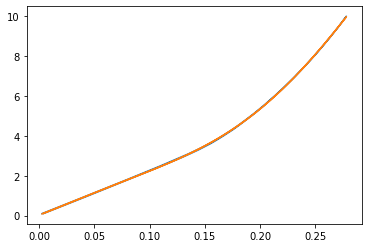

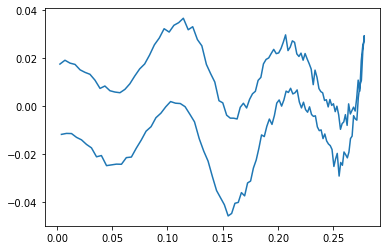

In [132]:
plt.plot(Bpfield0, Vpfield0)
plt.plot(Bpfield0, pfield_fit(Bpfield0))
plt.show()
plt.plot(Bpfield0,Vpfield0-pfield_fit(Bpfield0))
plt.show()

In [133]:
pfield_coeff

array([-9.76656401e+03,  6.48051441e+03, -1.08801588e+03,  6.45051622e+01,
        2.10276645e+01,  2.43525857e-02])

In [135]:
Bnfield0, Vnfield0= np.concatenate((VB_0.Yfield.values[:101],VB_0.Yfield.values[301:])), np.concatenate((VB_0.V.values[:101],VB_0.V.values[301:]))

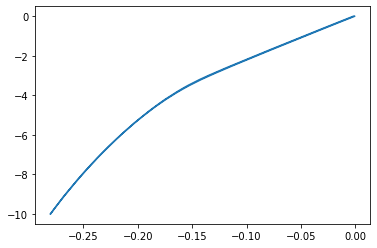

In [413]:
plt.plot(Bnfield0, Vnfield0)

### Seems like it would actually make sense just to fit the whole thing, idk the reason behind splitting up positive and negative fields...

In [176]:
allf_coeff = np.polyfit(VB_0.Yfield.values, VB_0.V.values, 9) # 9th order seems to fit the best
allf_fit = np.poly1d(allf_coeff)

In [414]:
allf_coeff

array([ 4.34304067e+05,  3.18296527e+03, -1.10304108e+05, -6.64937590e+02,
        1.02537779e+04,  4.71216545e+01, -1.67523674e+02, -4.49122936e-01,
        2.27663505e+01,  2.80189001e-02])

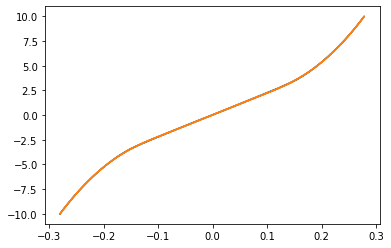

In [177]:
plt.plot(VB_0.Yfield.values, VB_0.V.values)
plt.plot(VB_0.Yfield.values, allf_fit(VB_0.Yfield.values))

Text(0.5, 1.0, 'Percent of deviation compared to full 10V')

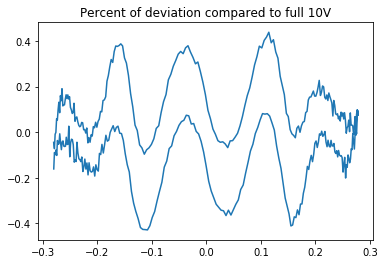

In [182]:
plt.plot(VB_0.Yfield.values, (VB_0.V.values-allf_fit(VB_0.Yfield.values))*10)
plt.title("Percent of deviation compared to full 10V")

# Radial Calibration

In [318]:
rad2V_bare = pd.read_csv('2019-11-22/shim_0deg_2V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad2V = pd.read_csv('2019-11-22/shim_0deg_2V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad2V.set_index('R',inplace=True)
rad4V = pd.read_csv('2019-11-22/shim_0deg_4V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad4V.set_index('R',inplace=True)
rad6V_bare = pd.read_csv('2019-11-22/shim_0deg_6V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad6V = pd.read_csv('2019-11-22/shim_0deg_6V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad6V.set_index('R',inplace=True)
rad8V = pd.read_csv('2019-11-22/shim_0deg_8V_daedalus_radialPolar_calib_A000.0_2019-11-22_1.csv',comment='#')
rad8V.set_index('R',inplace=True)

# rad2V_90 = pd.read_csv('2019-11-22/shim_90deg_2V_daedalus_radialPolar_calib_A090.0_2019-11-22_1.csv',comment='#')
# rad2V_90.set_index('R', inplace=True)

rad0 = combine_new_ds_dim(
    {
        2: xr.Dataset.from_dataframe(rad2V),
        4: xr.Dataset.from_dataframe(rad4V),
        6: xr.Dataset.from_dataframe(rad6V),
        8: xr.Dataset.from_dataframe(rad8V)
    },
    "V"
)

In [216]:
rad2V_90

,Xfield,Yfield,Zfield,theta,phi,B,elapsed_time
R,,,,,,,
-12.00,0.009267,0.001147,-0.062993,-81.464720,83.393962,0.063702,8.366479
-11.99,0.009378,0.001129,-0.062947,-81.537781,83.073590,0.063729,9.650552
-11.98,0.009294,0.001111,-0.063027,-81.484491,82.797926,0.063677,10.919625
-11.97,0.009431,0.001091,-0.062936,-81.425193,83.018835,0.063841,12.189697
-11.96,0.009448,0.001112,-0.063009,-81.445620,83.494104,0.063695,13.473771
...,...,...,...,...,...,...,...
14.96,0.011380,-0.003112,0.059020,78.741370,105.144831,0.060121,3433.389379
14.97,0.011399,-0.003091,0.059049,78.693799,105.104596,0.060130,3434.465440
14.98,0.011402,-0.003054,0.059005,78.718004,105.239055,0.060109,3435.539502


In [213]:
rad0.theta.where(rad0.theta==rad0.theta.max(),drop=True)

<xarray.DataArray 'theta' (V: 1, R: 1)>
array([[88.75888873]])
Coordinates:
  * R        (R) float64 14.12
  * V        (V) int64 2

Strange behavior beyond y=+14, so should probably just cap there

In [214]:
rad0 = rad0.where(rad0.R<=14., drop=True)

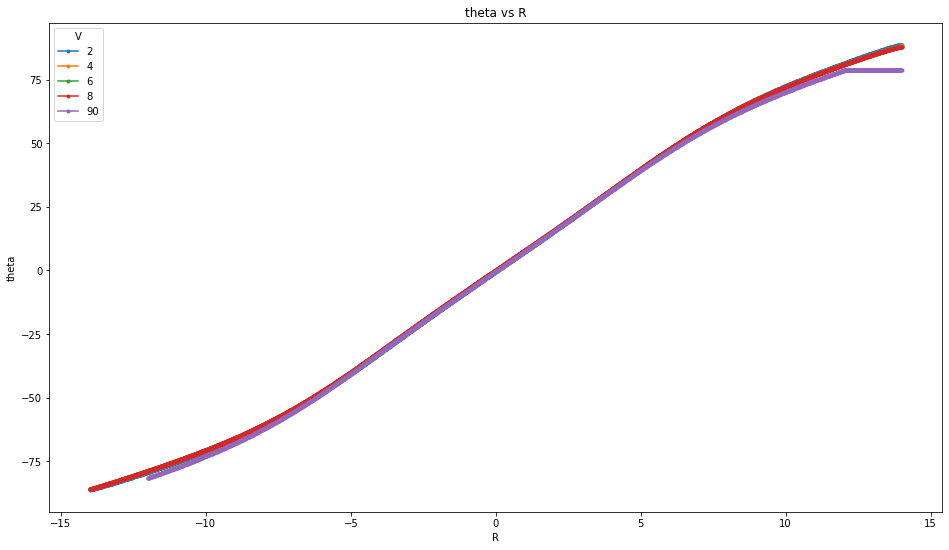

In [217]:
plt.figure(figsize=(16,9))
plot_dataset(rad0, 'R','theta', overlay=True, marker='.')

The $\theta(R)$ seems to be the same for all voltages, so will just fit to one of them. 90 deg one is not quite so nice, and it seems like a motion limit might have been hit.. will ignore it for now.

In [231]:
rad2V_R = rad2V_bare[rad2V_bare.R<=14]

In [269]:
rt_coeff = np.polyfit(rad2V_R.theta.values, rad2V_R.R.values, 7)
rt_fit = np.poly1d(rt_coeff)

In [416]:
rt_coeff

array([-7.79821729e-14,  2.89670072e-13,  1.78950126e-09, -1.28323113e-08,
       -4.95069272e-06,  2.16047415e-05,  1.27895026e-01,  5.07787261e-02])

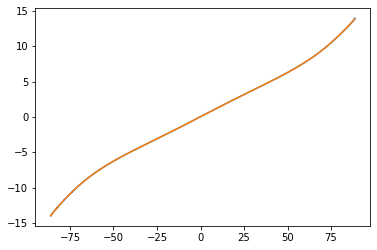

In [270]:
plt.plot(rad2V_R.theta, rad2V_R.R)
plt.plot(rad2V_R.theta, rt_fit(rad2V_R.theta))

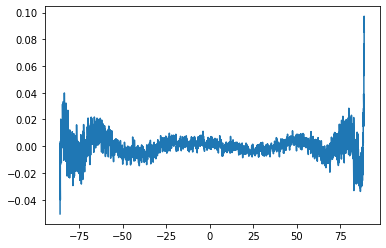

In [271]:
plt.plot(rad2V_R.theta, rad2V_R.R-rt_fit(rad2V_R.theta))

## Voltage Correction

In [307]:
B0=rad0.B.sel(R=-np.abs(rad0.R).min('R'))
B0

<xarray.DataArray 'B' (V: 4)>
array([0.08829113, 0.1659656 , 0.21305445, 0.24887519])
Coordinates:
    R        float64 -2.984e-13
  * V        (V) int64 2 4 6 8

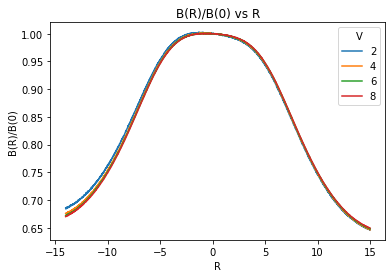

In [347]:
plot_dataArray(rad0.B/B0,'R',overlay=True,yname="B(R)/B(0)")

4,6,8 V all seem to be pretty close, so will use one of those. 2V isn't too far off either

In [335]:
# Field which would normally be requested at 6V
B6V = root(lambda x: allf_fit(x)-6, 0.2135).x[0]
B6V

0.213400978012341

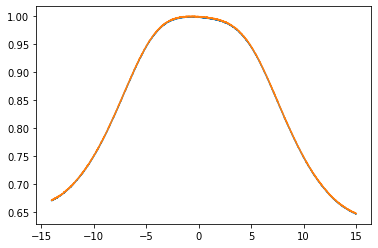

In [346]:
# Preimage of V(B) at V done in radial scan is basically the same as maximum B in radial scan (good)
plt.plot(rad6V_bare.R, rad6V_bare.B/B6V)
plt.plot(rad6V_bare.R, rad6V_bare.B/rad6V_bare.B.max())

In [407]:
BR_coeffs = np.polyfit(rad6V_bare.R.values, rad6V_bare.B.values/rad6V_bare.B.max(), 12)
BR_fit = np.poly1d(BR_coeffs)

In [417]:
BR_coeffs

array([-4.09189650e-14,  1.17557549e-13,  3.10432686e-11, -7.30095742e-11,
       -9.33477083e-09,  1.74113728e-08,  1.37688259e-06, -1.96142487e-06,
       -9.02840096e-05,  9.66251651e-05, -5.96450596e-04, -1.41877109e-03,
        9.99103675e-01])

In [408]:
BR_fit(0)

0.9991036748121659

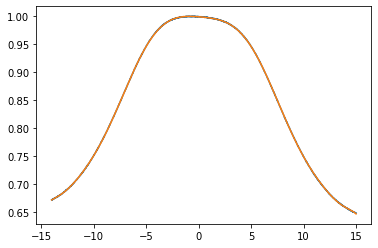

In [409]:
plt.plot(rad6V_bare.R, rad6V_bare.B/rad6V_bare.B.max())
plt.plot(rad6V_bare.R, BR_fit(rad6V_bare.R))

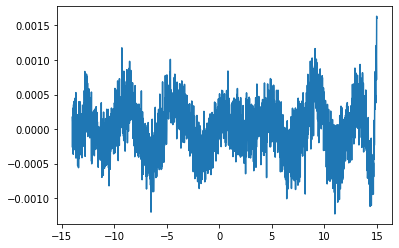

In [410]:
plt.plot(rad6V_bare.R, rad6V_bare.B/rad6V_bare.B.max()-BR_fit(rad6V_bare.R))

# Re-doing center calibration after taking out the shims

## coarse first

In [419]:
phi0ns = pd.read_csv('./2019-11-23/noshim_probeWireSide_coarse_0_fieldRaster_2019-11-23_1.csv',comment='#')
phi90ns = pd.read_csv('./2019-11-23/noshim_probeWireSide_coarse_90_fieldRaster_2019-11-23_1.csv',comment='#')

In [420]:
loxns = 10
hixns = 14
stepxns = 0.2
loyns = 12
hiyns = 16
stepyns = 0.2
xptsns = np.arange(loxns, hixns + stepxns, stepxns)
yptsns = np.arange(loyns, hiyns + stepyns, stepyns)

In [421]:
phi0ns_dv = {}
phi90ns_dv = {}
for c in phi0.columns:
    phi0ns_dv[c] = (["Yc", "Xc"], phi0ns[c].values.reshape(yptsns.size, xptsns.size))
    phi90ns_dv[c] = (["Yc", "Xc"], phi90ns[c].values.reshape(yptsns.size, xptsns.size))

In [422]:
coordsns = {'Xc': ('Xc', xptsns), 'Yc': ('Yc', yptsns)}

In [423]:
phi0ns_ds = xr.Dataset(phi0ns_dv, coordsns)
phi90ns_ds = xr.Dataset(phi90ns_dv, coordsns)

In [424]:
Zfieldns_mod = (phi90ns_ds.Zfield_avg**2 + phi0ns_ds.Zfield_avg**2)
print(Zfieldns_mod.where(Zfieldns_mod == Zfieldns_mod.min(), drop=True))
Zfieldns_mod.hvplot(title = "Combined 0 and 90 Z field")

<xarray.DataArray 'Zfield_avg' (Yc: 1, Xc: 1)>
array([[9.41648262e-06]])
Coordinates:
  * Xc       (Xc) float64 12.2
  * Yc       (Yc) float64 14.2


:Image   [Yc,Xc]   (Zfield_avg)

In [425]:
Yfieldns_mod = (phi90ns_ds.Xfield_avg**2 + phi0ns_ds.Yfield_avg**2)
print(Yfieldns_mod.where(Yfieldns_mod == Yfieldns_mod.max(), drop=True))
Yfieldns_mod.hvplot(title="Combined 0 and 90 Y field")

<xarray.DataArray (Yc: 1, Xc: 1)>
array([[0.10382299]])
Coordinates:
  * Xc       (Xc) float64 12.0
  * Yc       (Yc) float64 14.0


:Image   [Yc,Xc]   (value)

## Now fine

In [426]:
phi0nsf = pd.read_csv('./2019-11-23/noshim_probeWireSide_fine_0_fieldRaster_2019-11-23_1.csv',comment='#')
phi90nsf = pd.read_csv('./2019-11-23/noshim_probeWireSide_fine_90_fieldRaster_2019-11-23_1.csv',comment='#')

In [429]:
loxnsf = 11.8
hixnsf = 12.4
stepxnsf = 0.02
loynsf = 13.8
hiynsf = 14.4
stepynsf = 0.02
xptsnsf = np.arange(loxnsf, hixnsf + stepxnsf, stepxnsf)
yptsnsf = np.arange(loynsf, hiynsf + stepynsf, stepynsf)

In [430]:
phi0nsf_dv = {}
phi90nsf_dv = {}
for c in phi0nsf.columns:
    phi0nsf_dv[c] = (["Yc", "Xc"], phi0nsf[c].values.reshape(yptsnsf.size, xptsnsf.size))
    phi90nsf_dv[c] = (["Yc", "Xc"], phi90nsf[c].values.reshape(yptsnsf.size, xptsnsf.size))
    
coordsnsf = {'Xc': ('Xc', xptsnsf), 'Yc': ('Yc', yptsnsf)}

phi0nsf_ds = xr.Dataset(phi0nsf_dv, coordsnsf)
phi90nsf_ds = xr.Dataset(phi90nsf_dv, coordsnsf)

In [431]:
Zfieldnsf_mod = (phi90nsf_ds.Zfield_avg**2 + phi0nsf_ds.Zfield_avg**2)
print(Zfieldnsf_mod.where(Zfieldnsf_mod == Zfieldnsf_mod.min(), drop=True))
Zfieldnsf_mod.hvplot(title = "Combined 0 and 90 Z field")

<xarray.DataArray 'Zfield_avg' (Yc: 1, Xc: 1)>
array([[5.68907425e-08]])
Coordinates:
  * Xc       (Xc) float64 12.12
  * Yc       (Yc) float64 14.24


:Image   [Yc,Xc]   (Zfield_avg)

In [432]:
Yfieldnsf_mod = (phi90nsf_ds.Xfield_avg**2 + phi0nsf_ds.Yfield_avg**2)
print(Yfieldnsf_mod.where(Yfieldnsf_mod == Yfieldnsf_mod.max(), drop=True))
Yfieldnsf_mod.hvplot(title="Combined 0 and 90 Y field")

<xarray.DataArray (Yc: 1, Xc: 1)>
array([[0.10388445]])
Coordinates:
  * Xc       (Xc) float64 12.06
  * Yc       (Yc) float64 14.18


:Image   [Yc,Xc]   (value)

I'll go with the Z field since it's much cleaner

# Final center position: (12.12, 14.24)